In [2]:
import qiskit
import qiskit_ibm_runtime
import pylatexenc

from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit.circuit import Parameter
from qiskit.circuit.library import UGate
from qiskit.quantum_info import SparsePauliOp

import numpy as np
from numpy import pi

from itertools import product

from matplotlib import pyplot as plt

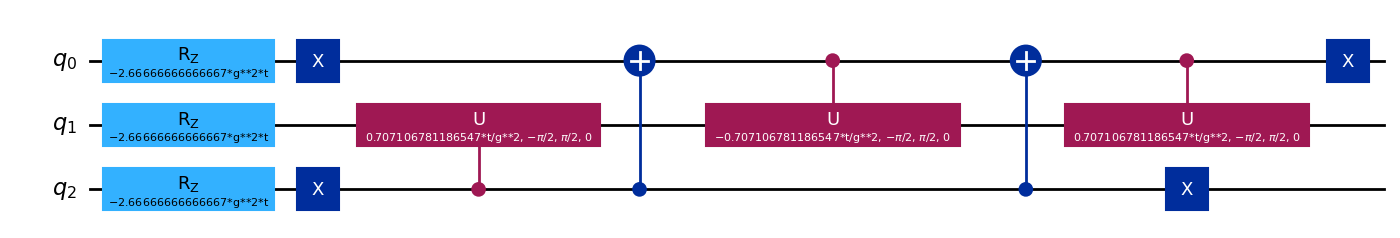

In [3]:
t = Parameter('t')
g = Parameter('g')
theta_E = (8 / 3) * g**2 * t
theta_B = 1 / (g**2 * np.sqrt(2)) * t

qc = QuantumCircuit(3)

# Electric term: Rz on each qubit
for q in range(3):
    qc.rz(-theta_E, q)

# Magnetic term: controlled on q0 and q2 = |0⟩, apply Rx to q1
# Flip controls from |0⟩ to |1⟩
qc.x(0)
qc.x(2)

# Apply controlled-Rx on q1, controlled by q0 and q2
qc.mcrx(2 * theta_B, [0, 2], 1)

# Flip back
qc.x(0)
qc.x(2)

qc.draw("mpl")

In [4]:
t = Parameter('t')
g = Parameter('g')

def generate_circuit_cnot(n):
    theta_E = (8 / 3) * g**2 * t
    theta_B = 1 / (g**2 * np.sqrt(2)) * t

    qc = QuantumCircuit(n)

    # Electric term: Rz on each qubit
    for q in range(n):
        qc.rz(-theta_E, q)

    # Magnetic term: controlled on q0 and q2 = |0⟩, apply Rx to q1
    for i in range(1, n-1):
        # Flip controls from |0⟩ to |1⟩
        qc.x(i-1)
        qc.x(i+1)

        # Apply controlled-Rx on q1, controlled by q0 and q2
        qc.mcrx(2 * theta_B, [i-1, i+1], i)

        # Flip back
        qc.x(i-1)
        qc.x(i+1)

    qc.draw("mpl")
    return qc

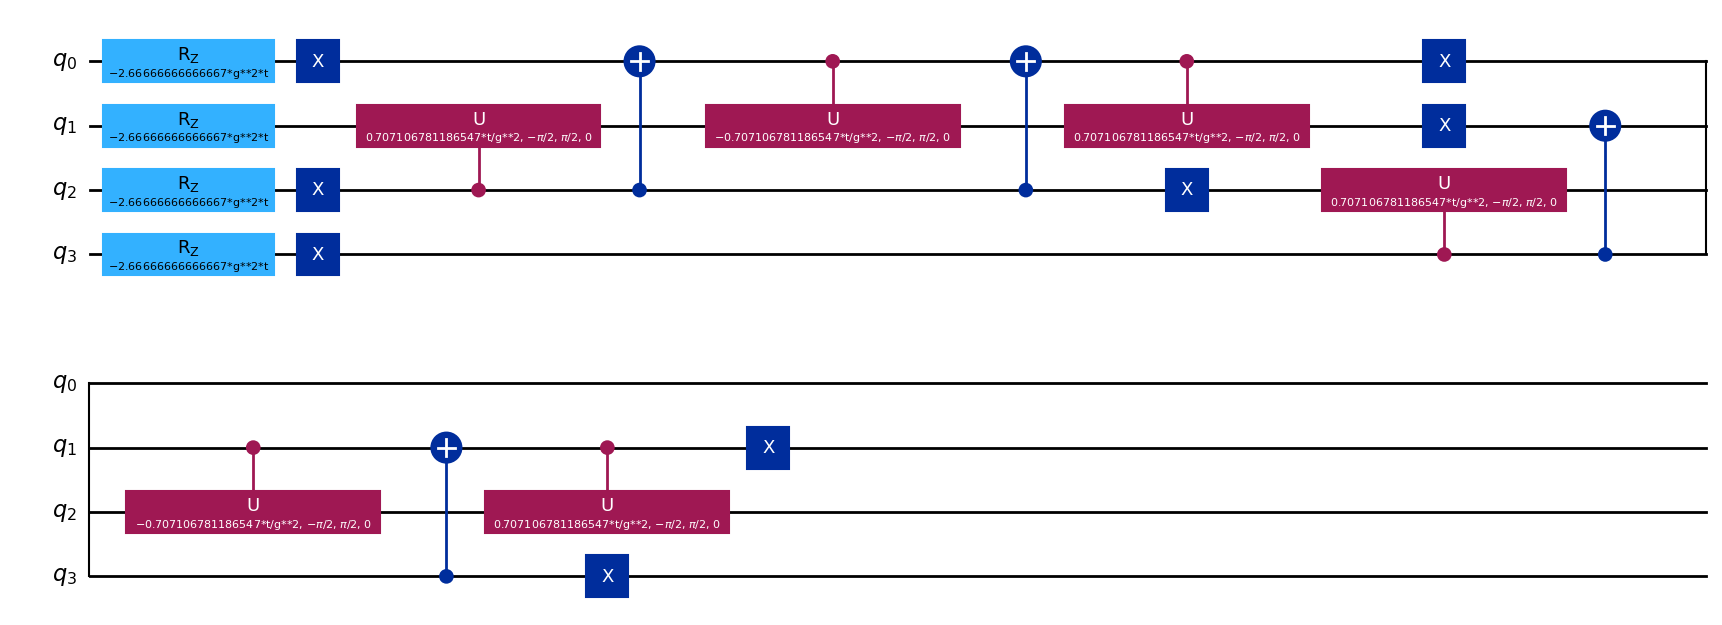

In [5]:
generate_circuit_cnot(3).draw("mpl")
generate_circuit_cnot(4).draw("mpl")

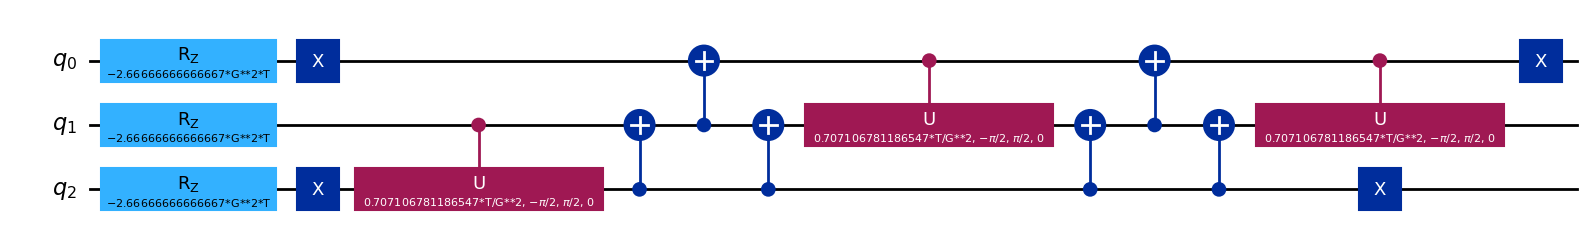

In [6]:
t = Parameter('T')
g = Parameter('G')
theta_E = (8 / 3) * g**2 * t
theta_B = 1 / (g**2 * np.sqrt(2)) * t

qc = QuantumCircuit(3)

# Electric term: Rz on each qubit
for q in range(3):
    qc.rz(-theta_E, q)

# Magnetic term: controlled on q0 and q2 = |0⟩, apply Rx to q1
# Flip controls from |0⟩ to |1⟩
qc.x(0)
qc.x(2)

# Construct the U gate
controlled_u = UGate(theta_B, -pi/2, pi/2).control(1)

# Frist U Gate prepares rotation
qc.append(controlled_u, [1, 2])

# First set of CNOTs
qc.cx(2, 1)
qc.cx(1, 0)
qc.cx(2, 1)

# Second U Gate does Rx rotation
qc.append(controlled_u, [0, 1])

# Second set of CNOTs
qc.cx(2, 1)
qc.cx(1, 0)
qc.cx(2, 1)

# Third U Gate undoes preparation
qc.append(controlled_u, [0, 1])

# Flip back
qc.x(0)
qc.x(2)

qc.draw("mpl")

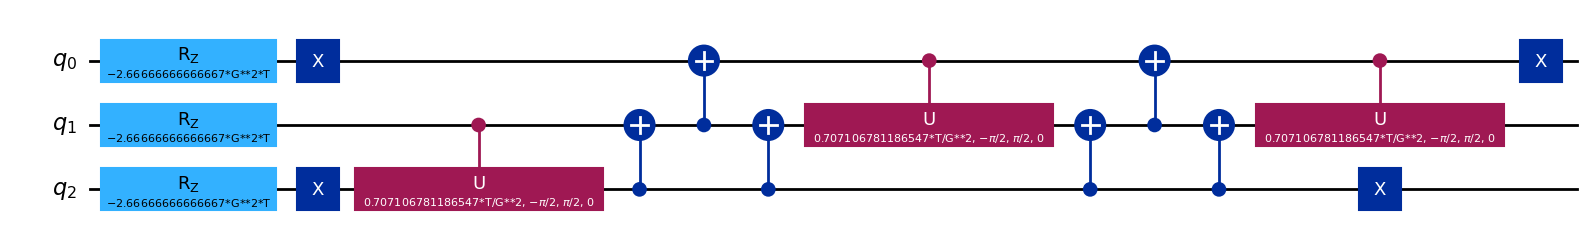

In [7]:
# Argument n is the number of given qubits
t = Parameter('T')
g = Parameter('G')

def generate_circuit(n):
    theta_E = (8 / 3) * g**2 * t
    theta_B = 1 / (g**2 * np.sqrt(2)) * t

    qc = QuantumCircuit(n)

    for q in range(n):
        qc.rz(-theta_E, q)

    # Loop through qubit 1 to qubit n-1
    for i in range(1, n-1):
        qc.x(i-1)
        qc.x(i+1)

        controlled_u = UGate(theta_B, -pi/2, pi/2).control(1)

        qc.append(controlled_u, [i, i+1])

        qc.cx(i+1, i)
        qc.cx(i, i-1)
        qc.cx(i+1, i)

        qc.append(controlled_u, [i-1, i])

        qc.cx(i+1, i)
        qc.cx(i, i-1)
        qc.cx(i+1, i)

        qc.append(controlled_u, [i-1, i])

        qc.x(i-1)
        qc.x(i+1)

    qc.draw("mpl")
    # Return the circuit
    return qc

generate_circuit(3).draw("mpl")

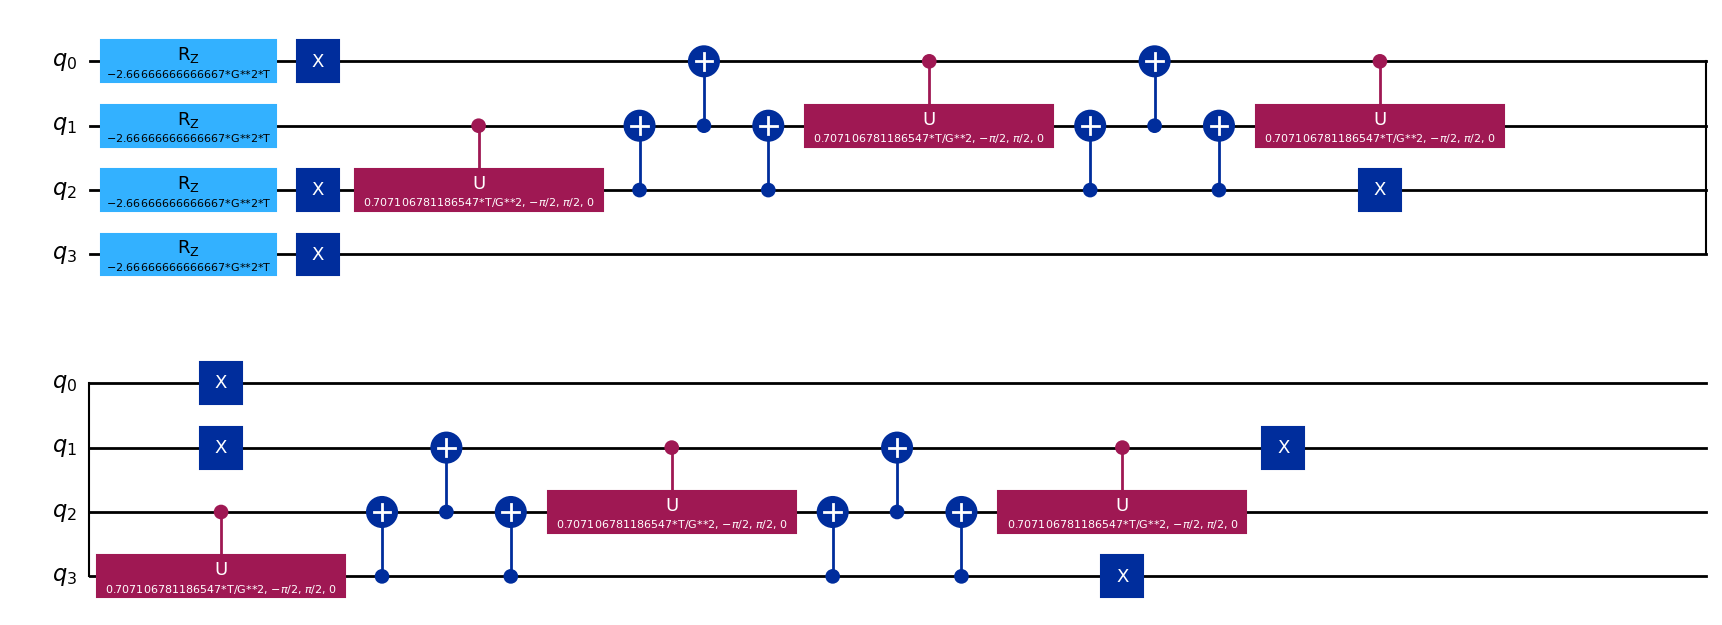

In [8]:
generate_circuit(4).draw("mpl")

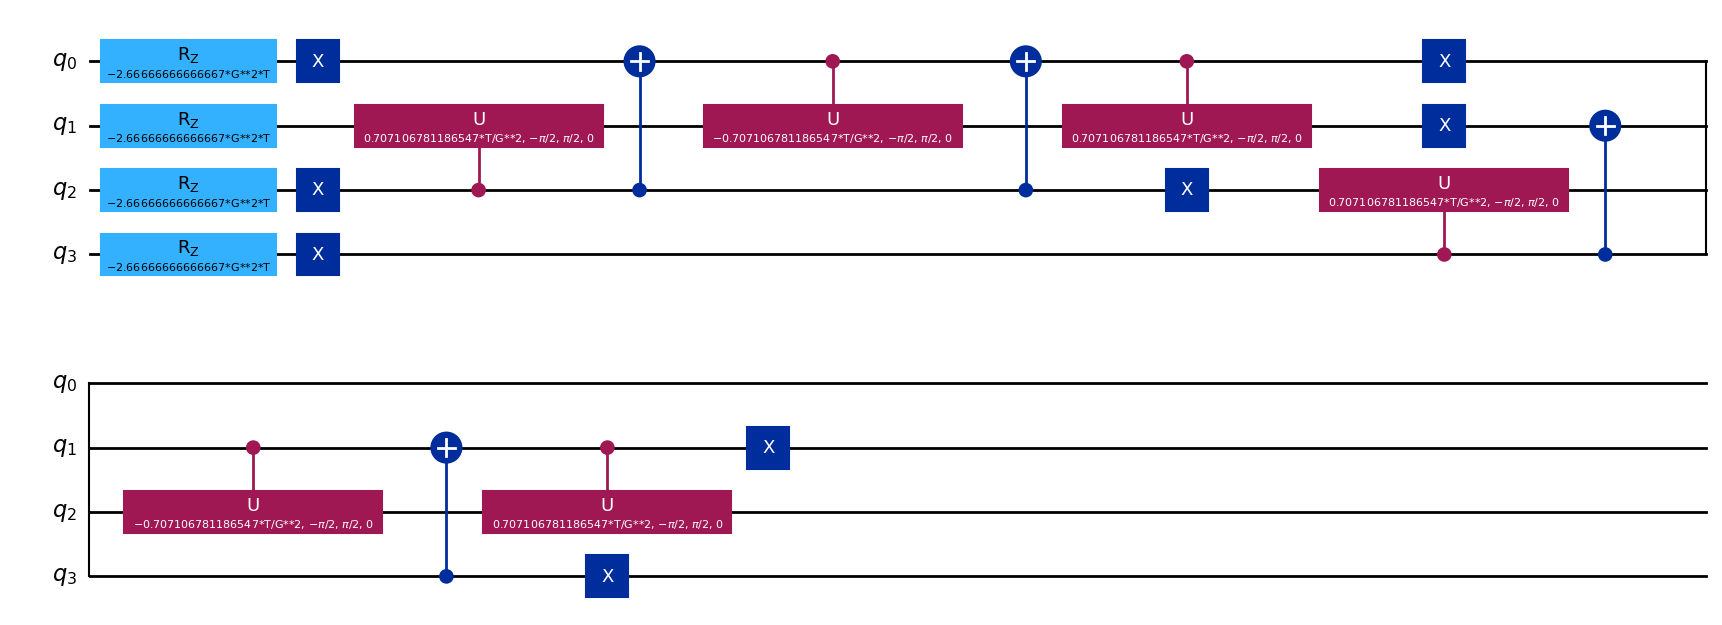

In [9]:
generate_circuit_cnot(4).draw("mpl")

In [10]:
# Generate all combinations of 3 Pauli operators
pauli_labels = [''.join(p) for p in product('IXYZ', repeat=3)]

# Create SparsePauliOp objects for each
observables = [SparsePauliOp(label) for label in pauli_labels]
observables_labels = pauli_labels

In [11]:
qc = generate_circuit(3)
qc = qc.assign_parameters({g:1., t:1.})

# Use the following code instead if you want to run on a simulator:
 
from qiskit_ibm_runtime.fake_provider import FakeAlmadenV2
backend = FakeAlmadenV2()
estimator = Estimator(backend)
 
# Convert to an ISA circuit and layout-mapped observables.
 
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc)
mapped_observables = [
    observable.apply_layout(isa_circuit.layout) for observable in observables
]
 
job = estimator.run([(isa_circuit, mapped_observables)])
result = job.result()
 
# This is the result of the entire submission.  You submitted one Pub,
# so this contains one inner result (and some metadata of its own).
 
job_result = job.result()
 
# This is the result from our single pub, which had five observables,
# so contains information on all five.
 
pub_result = job.result()[0]

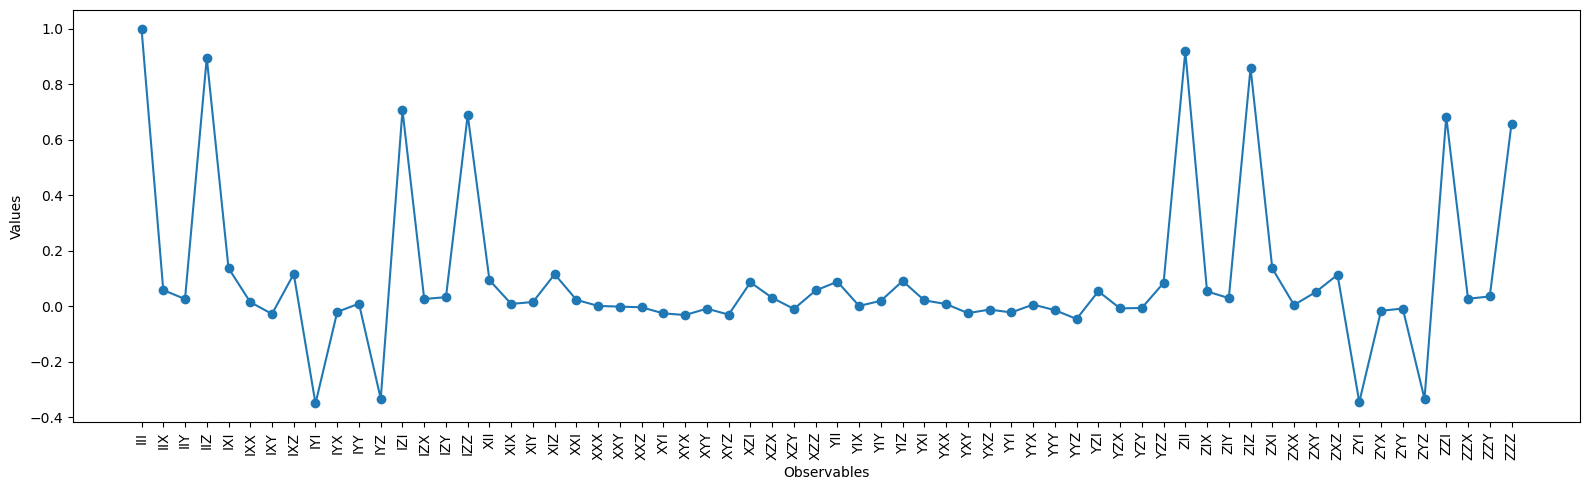

In [22]:
values = pub_result.data.evs
errors = pub_result.data.stds

# Set figure size: (width, height) in inches
plt.figure(figsize=(16, 5))

# Plotting
plt.plot(observables_labels, values, "-o")
plt.xlabel("Observables")
plt.ylabel("Values")
plt.xticks(rotation=90)  # Optional: rotate x-axis labels for readability
plt.tight_layout()
plt.savefig('test0.png')
plt.show()

In [ ]:
qc = generate_circuit(3)
qc = qc.assign_parameters({g:1., t:1.})
 
# Use the following code instead if you want to run on a simulator:
 
from qiskit_ibm_runtime.fake_provider import FakeAlmadenV2
backend = FakeAlmadenV2()
estimator = Estimator(backend)
 
# Convert to an ISA circuit and layout-mapped observables.
 
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc)
mapped_observables = [
    observable.apply_layout(isa_circuit.layout) for observable in observables
]
 
job = estimator.run([(isa_circuit, mapped_observables)])
result = job.result()
 
# This is the result of the entire submission.  You submitted one Pub,
# so this contains one inner result (and some metadata of its own).
 
job_result = job.result()
 
# This is the result from our single pub, which had five observables,
# so contains information on all five.
 
pub_result = job.result()[0]

In [ ]:
values = pub_result.data.evs
errors = pub_result.data.stds

# Set figure size: (width, height) in inches
plt.figure(figsize=(16, 5))

# Plotting
plt.plot(observables_labels, values, "-o")
plt.xlabel("Observables")
plt.ylabel("Values")
plt.xticks(rotation=90)  # Optional: rotate x-axis labels for readability
plt.tight_layout()
plt.savefig('test1.png')
plt.show()

In [18]:
observables_labels = ["IZI", "ZZI", "IZZ", "ZIZ"]
observables = [SparsePauliOp(label) for label in observables_labels]

In [20]:
qc = generate_circuit(3, 1)
qc = qc.assign_parameters({g:1., t:1.})

from qiskit_ibm_runtime.fake_provider import FakeAlmadenV2
backend = FakeAlmadenV2()
estimator = Estimator(backend)
 
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc)
mapped_observables = [
    observable.apply_layout(isa_circuit.layout) for observable in observables
]
 
job = estimator.run([(isa_circuit, mapped_observables)])
result = job.result()
 
job_result = job.result()
 
pub_result = job.result()[0]

NameError: name 'generate_circuit' is not defined